In [1]:
import numpy as np
from pandas import Series,DataFrame
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV  #搜索核实的参数
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import MinMaxScaler,StandardScaler

导入数据

In [189]:
X,y = datasets.load_breast_cancer(return_X_y=True)
x_colname = datasets.load_breast_cancer().feature_names
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)


使用网格搜索

In [192]:
knn = KNeighborsClassifier()
params =[
    {
        'weights':['uniform'],
        'n_neighbors':[i for i in range(1,11)]
    },
    {
        'weights':['distance'],
        'n_neighbors':[i for i in range(1,11)],
        'p':[i for i in range(1,6)]
    }
]

gcv = GridSearchCV(knn,param_grid=params,scoring='accuracy',cv=6,n_jobs=-1)  #'weight':['distance','uniform'],
gcv.fit(X_train,y_train)

GridSearchCV(cv=6, estimator=KNeighborsClassifier(), n_jobs=-1,
             param_grid=[{'n_neighbors': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
                          'weights': ['uniform']},
                         {'n_neighbors': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
                          'p': [1, 2, 3, 4, 5], 'weights': ['distance']}],
             scoring='accuracy')

In [168]:
gcv.best_estimator_
gcv.best_score_
gcv.best_params_
y_ = gcv.predict(X_test)
y_

array([0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1,
       1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1,
       1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0,
       1, 1, 0, 1])

In [169]:
(y_ == y_test).mean()

0.9473684210526315

In [171]:
accuracy_score(y_test,y_,)

0.9473684210526315

In [172]:
knn_best = gcv.best_estimator_
y2_ = knn_best.predict(X_test)
y2_

array([0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1,
       1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1,
       1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0,
       1, 1, 0, 1])

学习numpy

In [130]:
arr1 = np.random.randint(0,10,size=(4,5)) 
arr2 = np.arange(1,11).reshape(2,5)
# arr3 = np.array([1,3,[3,5,8]])

In [41]:
display(arr1,arr2)

array([[8, 3, 0, 7, 6],
       [0, 5, 1, 1, 9],
       [7, 1, 3, 8, 8],
       [0, 4, 2, 9, 5]])

array([[ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10],
       [11, 12, 13, 14, 15, 16, 17, 18, 19, 20]])

In [135]:
np.array_split(arr1,2,axis=1)
np.argwhere(arr1 > 5)
np.where((arr1>5),arr1,0)
arr1[arr1 < 5] = 0

np.argmax(arr1,axis=0)
# np.max(arr1,axis=0)


array([7, 9, 9, 9, 8])

In [134]:
arr1

array([[0, 8, 7, 9, 0],
       [7, 0, 0, 8, 0],
       [6, 0, 6, 5, 8],
       [6, 9, 9, 0, 8]])

(774, 652, 4)

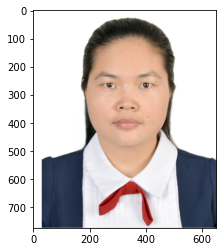

In [94]:
import matplotlib.pyplot as plt
ndarr = plt.imread("./datas/ZJH1908.PNG")
plt.imshow(ndarr)
# 接下来展示的是几个属性 
ndarr.ndim # 多少个维度
ndarr.shape # 形状 273 411 3
ndarr.size # 总共有多少个元素 273*411*3
ndarr.shape

交叉表

In [175]:
pd.crosstab(index=y_test,columns=y_,rownames=['True'],margins=True)

col_0,0,1,All
True,,,
0,32,5,37
1,1,76,77
All,33,81,114


In [176]:
from sklearn.metrics import confusion_matrix
confusion_matrix(y_test,y_)

array([[32,  5],
       [ 1, 76]], dtype=int64)

In [179]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_,target_names=['B','M']))


              precision    recall  f1-score   support

           B       0.97      0.86      0.91        37
           M       0.94      0.99      0.96        77

    accuracy                           0.95       114
   macro avg       0.95      0.93      0.94       114
weighted avg       0.95      0.95      0.95       114



In [ ]:
提升准确率，精确率，召回率，数据做归一化处理

In [187]:
X_normal = (X - X.min(axis=0)) /(X.max(axis=0) - X.min(axis=0))
X_normal


array([[0.52103744, 0.0226581 , 0.54598853, ..., 0.91202749, 0.59846245,
        0.41886396],
       [0.64314449, 0.27257355, 0.61578329, ..., 0.63917526, 0.23358959,
        0.22287813],
       [0.60149557, 0.3902604 , 0.59574321, ..., 0.83505155, 0.40370589,
        0.21343303],
       ...,
       [0.45525108, 0.62123774, 0.44578813, ..., 0.48728522, 0.12872068,
        0.1519087 ],
       [0.64456434, 0.66351031, 0.66553797, ..., 0.91065292, 0.49714173,
        0.45231536],
       [0.03686876, 0.50152181, 0.02853984, ..., 0.        , 0.25744136,
        0.10068215]])

In [191]:
display(X_normal.shape,y.shape)

(569, 30)

(569,)

In [194]:
X_train,X_test,y_train,y_test = train_test_split(X_normal,y,test_size=0.2)
knn = KNeighborsClassifier()
params =[
    {
        'weights':['uniform'],
        'n_neighbors':[i for i in range(1,11)]
    },
    {
        'weights':['distance'],
        'n_neighbors':[i for i in range(1,11)],
        'p':[i for i in range(1,6)]
    }
]
gcv = GridSearchCV(knn,param_grid=params,scoring='accuracy',cv=6,n_jobs=-1)
gcv.fit(X_train,y_train)

GridSearchCV(cv=6, estimator=KNeighborsClassifier(), n_jobs=-1,
             param_grid=[{'n_neighbors': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
                          'weights': ['uniform']},
                         {'n_neighbors': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
                          'p': [1, 2, 3, 4, 5], 'weights': ['distance']}],
             scoring='accuracy')

In [196]:
y_ = gcv.predict(X_test)
accuracy_score(y_test,y_)

0.9473684210526315

In [198]:
print(classification_report(y_test,y_))

              precision    recall  f1-score   support

           0       0.98      0.90      0.94        49
           1       0.93      0.98      0.96        65

    accuracy                           0.95       114
   macro avg       0.95      0.94      0.95       114
weighted avg       0.95      0.95      0.95       114



另一种归一化：z-score归一化

In [204]:
df = pd.DataFrame(X)
X_normal2 = (df - df.mean())/df.std()


In [209]:
X_normal2.mean()
X_normal2.std()

0     1.0
1     1.0
2     1.0
3     1.0
4     1.0
5     1.0
6     1.0
7     1.0
8     1.0
9     1.0
10    1.0
11    1.0
12    1.0
13    1.0
14    1.0
15    1.0
16    1.0
17    1.0
18    1.0
19    1.0
20    1.0
21    1.0
22    1.0
23    1.0
24    1.0
25    1.0
26    1.0
27    1.0
28    1.0
29    1.0
dtype: float64

In [205]:
X_train,X_test,y_train,y_test = train_test_split(X_normal2,y,test_size=0.2)
knn = KNeighborsClassifier()
params =[
    {
        'weights':['uniform'],
        'n_neighbors':[i for i in range(1,11)]
    },
    {
        'weights':['distance'],
        'n_neighbors':[i for i in range(1,11)],
        'p':[i for i in range(1,6)]
    }
]
gcv = GridSearchCV(knn,param_grid=params,scoring='accuracy',cv=6,n_jobs=-1)
gcv.fit(X_train,y_train)

GridSearchCV(cv=6, estimator=KNeighborsClassifier(), n_jobs=-1,
             param_grid=[{'n_neighbors': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
                          'weights': ['uniform']},
                         {'n_neighbors': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
                          'p': [1, 2, 3, 4, 5], 'weights': ['distance']}],
             scoring='accuracy')

In [206]:
y_ = gcv.predict(X_test)
accuracy_score(y_test,y_)

0.956140350877193

In [207]:
print(classification_report(y_test,y_))

              precision    recall  f1-score   support

           0       0.98      0.92      0.95        49
           1       0.94      0.98      0.96        65

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



sklearn中的归一化处理

In [213]:
mms = MinMaxScaler()
mms.fit(df)
X2 = mms.fit_transform(df)
X2

array([[0.52103744, 0.0226581 , 0.54598853, ..., 0.91202749, 0.59846245,
        0.41886396],
       [0.64314449, 0.27257355, 0.61578329, ..., 0.63917526, 0.23358959,
        0.22287813],
       [0.60149557, 0.3902604 , 0.59574321, ..., 0.83505155, 0.40370589,
        0.21343303],
       ...,
       [0.45525108, 0.62123774, 0.44578813, ..., 0.48728522, 0.12872068,
        0.1519087 ],
       [0.64456434, 0.66351031, 0.66553797, ..., 0.91065292, 0.49714173,
        0.45231536],
       [0.03686876, 0.50152181, 0.02853984, ..., 0.        , 0.25744136,
        0.10068215]])

In [219]:
ss = StandardScaler()
X3 = ss.fit_transform(df)
np.round(X3.mean(axis=0),6)

array([-0., -0., -0., -0.,  0., -0., -0.,  0., -0., -0., -0., -0.,  0.,
       -0., -0., -0.,  0., -0., -0., -0., -0.,  0., -0.,  0., -0., -0.,
        0., -0., -0.,  0.])